# Лабораторная работа №6: Построение и оценка VLM-пайплайна

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


### Математическая постановка

Для открытых ответов одной exact match недостаточно. Используют нормализованный EM/F1, judge rubric и ручную разметку ошибок. Hallucination rate: $H=N_{unsupported}/N_{claims}$.


### Материалы

- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal)
- [VLMEvalKit](https://github.com/open-compass/VLMEvalKit)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\eric1\\Desktop\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
# === Этап 1: оценочный набор с происхождением (с кэшем: сеть нужна только один раз) ===
eval_path = ARTIFACTS / "eval.jsonl"

if eval_path.exists():
    examples = [json.loads(l) for l in eval_path.read_text(encoding="utf-8").splitlines() if l.strip()]
    if FAST_DEV_RUN and len(examples) > 4:  # для smoke-режима берём по 1 примеру с категории
        seen, subset = set(), []
        for ex in examples:
            if ex["category"] not in seen:
                seen.add(ex["category"]); subset.append(ex)
        examples = subset
    print(f"Кэш найден: беру {len(examples)} примеров из eval.jsonl (сеть не нужна)")
else:
    from open_eval_data import load_open_eval
    per_task = 1 if FAST_DEV_RUN else None
    examples = load_open_eval(root="data/lab06", per_task=per_task)
    with eval_path.open("w", encoding="utf-8") as f:
        for ex in examples:
            f.write(json.dumps(ex, ensure_ascii=False) + "\n")

cats = {}
for ex in examples:
    cats[ex["category"]] = cats.get(ex["category"], 0) + 1

expected = 4 if FAST_DEV_RUN else 20
check(len(examples) == expected, f"размер набора {len(examples)}/{expected}")
for c in ("caption", "open_vqa", "document_qa", "object_count_json"):
    check(c in cats, f"категория {c}: {cats.get(c, 0)}")
check(all(Path(ex["image"]).is_file() for ex in examples), "все изображения существуют локально")
prov_ok = all(ex.get("source") and ex.get("source_split") and ex.get("license") for ex in examples)
check(prov_ok, "происхождение заполнено (source, split, license)")
print(f"✔ eval.jsonl: {eval_path.resolve()} ({len(examples)} записей)")

Кэш найден: беру 20 примеров из eval.jsonl (сеть не нужна)
✔ размер набора 20/20
✔ категория caption: 5
✔ категория open_vqa: 5
✔ категория document_qa: 5
✔ категория object_count_json: 5
✔ все изображения существуют локально
✔ происхождение заполнено (source, split, license)
✔ eval.jsonl: C:\Users\eric1\Desktop\SOTA\lab6\artifacts\eval.jsonl (20 записей)


### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# Сетевой фикс: доверять системным сертификатам Windows (антивирус/прокси с self-signed CA)
try:
    import truststore
    truststore.inject_into_ssl()
    print("✔ truststore: используем системные сертификаты Windows")
except Exception as e:
    print(f"✘ truststore недоступен ({e}) — SSL может падать")
import transformers
from transformers import AutoProcessor, BitsAndBytesConfig

try:  # в новых версиях класс переименован
    from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError:
    from transformers import AutoModelForVision2Seq as AutoVLM

try:
    import bitsandbytes  # noqa: F401
    HAS_BNB = True
except ImportError:
    HAS_BNB = False
AutoModelForVision2Seq = AutoVLM  # алиас: старые вызовы продолжают работать
MODEL_ID = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
if DEVICE != "cuda" and not FAST_DEV_RUN:
    raise RuntimeError("Полный режим требует GPU с CUDA для NF4-инференса — см. профиль вычислений лабы.")

processor = AutoProcessor.from_pretrained(MODEL_ID)

PRECISION = None
if DEVICE == "cuda":
    if HAS_BNB:
        bnb = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16,
        )
        try:
            model = AutoModelForVision2Seq.from_pretrained(MODEL_ID, quantization_config=bnb, device_map="auto")
            PRECISION = "nf4"
        except Exception as e:
            print(f"✘ NF4 не удался ({type(e).__name__}: {e}); перехожу на fp16")
    if PRECISION is None:
        model = AutoModelForVision2Seq.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="auto")
        PRECISION = "fp16 (fallback, NF4 недоступен)"
else:
    model = AutoModelForVision2Seq.from_pretrained(MODEL_ID, torch_dtype=torch.float32).to("cpu")
    PRECISION = "fp32-cpu (только smoke-проверка)"
model.eval()

info = {"model_id": MODEL_ID, "precision": PRECISION, "device": DEVICE,
        "transformers": transformers.__version__, "torch": torch.__version__,
        "bitsandbytes": bitsandbytes.__version__ if HAS_BNB else None}
(ARTIFACTS / "model_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(info, ensure_ascii=False, indent=2))
if DEVICE == "cuda":
    print(f"Память CUDA под модель: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")
print("✔ processor, model, model_id готовы")

✔ truststore: используем системные сертификаты Windows


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

{
  "model_id": "HuggingFaceTB/SmolVLM2-2.2B-Instruct",
  "precision": "nf4",
  "device": "cuda",
  "transformers": "4.57.6",
  "torch": "2.6.0+cu124",
  "bitsandbytes": "0.50.2"
}
Память CUDA под модель: 1.45 GiB
✔ processor, model, model_id готовы


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
GEN_FULL = {"max_new_tokens": 128, "do_sample": False}
GEN_FAST = {"max_new_tokens": 32, "do_sample": False}

def build_prompt(image, question):
    """Сообщение с изображением: image-токен строго ПЕРЕД текстом вопроса."""
    return [{"role": "user", "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": str(question)},
    ]}]

@torch.inference_mode()
def run_vlm(image, question, gen_overrides=None):
    """Инференс VLM: возвращает (сырой ответ, метаданные с временем generate)."""
    gen = dict(GEN_FAST if FAST_DEV_RUN else GEN_FULL)
    gen.update(gen_overrides or {})
    text = processor.apply_chat_template(build_prompt(image, question), add_generation_prompt=True)
    inputs = processor(text=text, images=[image], return_tensors="pt").to(model.device)
    t0 = time.perf_counter()
    out = model.generate(**inputs, **gen)
    latency = time.perf_counter() - t0
    n_in = inputs["input_ids"].shape[1]
    raw = processor.batch_decode(out[:, n_in:], skip_special_tokens=True)[0].strip()
    return raw, {"latency_s": round(latency, 3), "new_tokens": int(out.shape[1] - n_in), "gen_params": gen}

print("✔ build_prompt и run_vlm готовы")


✔ build_prompt и run_vlm готовы


### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
from PIL import Image

pred_path = ARTIFACTS / "predictions.jsonl"

def read_jsonl(path):
    rows = []
    if Path(path).exists():
        for line in Path(path).read_text(encoding="utf-8").splitlines():
            if line.strip():
                rows.append(json.loads(line))
    return rows

done = {r["id"]: r for r in read_jsonl(pred_path)}
if done:
    print(f"Найден checkpoint: {len(done)} готовых предсказаний — пропускаю")

records, t_start = [], time.perf_counter()
with pred_path.open("a", encoding="utf-8") as f:
    for i, ex in enumerate(examples):
        ex_id = f'{ex["task"]}-{ex["source_row"]}'
        rec = done.get(ex_id)
        if rec is None:
            image = Image.open(ex["image"]).convert("RGB")
            pred, meta = run_vlm(image, ex["question"])
            rec = {"id": ex_id, "category": ex["category"], "task": ex["task"],
                   "question": ex["question"], "reference": ex["reference"], "image": ex["image"],
                   "prediction": pred, "model_id": MODEL_ID, "precision": PRECISION, **meta}
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            print(f"[{i + 1}/{len(examples)}] {ex_id} ({meta['latency_s']}s): {pred[:70]}")
        records.append(rec)

(ARTIFACTS / "predictions.json").write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
check(len(records) == len(examples), f"предсказаний {len(records)}/{len(examples)}")
print(f"✔ predictions.jsonl/json сохранены; инференс {time.perf_counter() - t_start:.0f}s (без уже готовых)")

Найден checkpoint: 20 готовых предсказаний — пропускаю
✔ предсказаний 20/20
✔ predictions.jsonl/json сохранены; инференс 0s (без уже готовых)


### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
import re, string

def norm_text(s):
    s = str(s).lower().strip()
    s = s.translate(str.maketrans("", "", string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def exact_match(pred, ref):
    return float(norm_text(pred) == norm_text(ref))

def token_f1(pred, ref):
    p, r = norm_text(pred).split(), norm_text(ref).split()
    if not p or not r:
        return float(not p and not r)
    common = set(p) & set(r)
    if not common:
        return 0.0
    prec, rec = len(common) / len(p), len(common) / len(r)
    return 2 * prec * rec / (prec + rec)

def parse_json_lenient(s):
    s = str(s)
    i, j = s.find("{"), s.rfind("}")
    if i == -1 or j <= i:
        return None
    try:
        return json.loads(s[i:j + 1])
    except Exception:
        return None

by_cat = {}
for rec in records:
    d = by_cat.setdefault(rec["category"], {"n": 0, "em": 0.0, "f1": 0.0})
    d["n"] += 1
    if rec["category"] in ("open_vqa", "document_qa"):
        d["em"] += exact_match(rec["prediction"], rec["reference"])
        d["f1"] += token_f1(rec["prediction"], rec["reference"])
    elif rec["category"] == "object_count_json":
        pj, rj = parse_json_lenient(rec["prediction"]), json.loads(rec["reference"])
        d["em"] += float(pj == rj)
        d["f1"] += float(isinstance(pj, dict) and pj.get("count") == rj.get("count"))
    # caption: строковую метрику не считаем — нужна ручная оценка (этапы 6-7)

for d in by_cat.values():
    d["em"] = round(d["em"] / d["n"], 4)
    d["f1"] = round(d["f1"] / d["n"], 4)

metrics = {"mode": "fast_dev_run" if FAST_DEV_RUN else "full", "n_examples": len(records),
           "by_category": by_cat,
           "note": ("smoke-проверка, не отчётные числа" if FAST_DEV_RUN else
                    "EM/F1 после нормализации (регистр, пунктуация, артикли); для object_count_json: "
                    "em = точное совпадение JSON, f1 = совпадение count; caption исключён — ручная оценка")}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(by_cat, ensure_ascii=False, indent=2))
print("✔ metrics.json сохранён")

{
  "caption": {
    "n": 5,
    "em": 0.0,
    "f1": 0.0
  },
  "open_vqa": {
    "n": 5,
    "em": 0.0,
    "f1": 0.1145
  },
  "document_qa": {
    "n": 5,
    "em": 0.4,
    "f1": 0.6164
  },
  "object_count_json": {
    "n": 5,
    "em": 0.2,
    "f1": 0.2
  }
}
✔ metrics.json сохранён


EM = совпало дословно, F1 = доля общих слов.

document_qa - Лучший предмет: чтение текста с документа — механика, ответы короткие («$2,500»), 2 из 5 дословно
object_count_json - Слабое место: правильный счёт только в 1 из 5 — типичная болезнь VLM
open_vqa - Ни один ответ не совпал дословно — но это не приговор, см. ниже
caption	- Это не «всё описал неправильно» — метрика тут не считалась намеренно: описание нельзя мерить дословным совпадением

### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
ERROR_TYPES = ["hallucination", "ocr", "spatial", "counting", "other", "none"]
review_path = ARTIFACTS / "manual_review.jsonl"
existing = {r["id"]: r for r in read_jsonl(review_path)}

rows = []
for rec in records:
    old = existing.get(rec["id"], {})
    rows.append({"id": rec["id"], "category": rec["category"], "image": rec["image"],
                 "question": rec["question"], "reference": rec["reference"], "prediction": rec["prediction"],
                 "correctness": old.get("correctness"),   # true / false / null
                 "error_type": old.get("error_type"),     # из ERROR_TYPES / null
                 "comment": old.get("comment", "")})

with review_path.open("w", encoding="utf-8") as f:
    for r in rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

filled = sum(r["correctness"] is not None for r in rows)
print(f"✔ manual_review.jsonl: {len(rows)} строк, размечено {filled}, осталось {len(rows) - filled}")
print("Открой файл в VS Code, проставь correctness (true/false), error_type и comment, затем перезапусти следующую ячейку.")

✔ manual_review.jsonl: 20 строк, размечено 20, осталось 0
Открой файл в VS Code, проставь correctness (true/false), error_type и comment, затем перезапусти следующую ячейку.


In [9]:
# === Интерактивная форма экспертной разметки (ipywidgets) ===
import html as _html
import ipywidgets as W
from IPython.display import display

rows = read_jsonl(review_path)
ERROR_TYPES = ["hallucination", "ocr", "spatial", "counting", "other", "none"]

correctness_w = W.RadioButtons(options=[("верно", True), ("неверно", False), ("—", None)],
                               value=None, description="Оценка:")
error_w = W.Dropdown(options=["—"] + ERROR_TYPES, value="—", description="Тип ошибки:")
comment_w = W.Text(description="Комментарий:")
img_w = W.Image(format="jpeg"); img_w.width = 420
info_w = W.HTML(); progress_w = W.HTML()
btn_prev = W.Button(description="← Назад")
btn_save = W.Button(description="Сохранить →", button_style="success")
btn_skip = W.Button(description="Пропустить →")

def save_all():
    cur = rows[state["i"]]
    cur["correctness"] = correctness_w.value
    cur["error_type"] = None if error_w.value == "—" else error_w.value
    cur["comment"] = comment_w.value.strip()
    with review_path.open("w", encoding="utf-8") as f:
        for x in rows:
            f.write(json.dumps(x, ensure_ascii=False) + "\n")

def show(i):
    state["i"] = i % len(rows)
    r = rows[state["i"]]
    img_w.value = Path(r["image"]).read_bytes()
    info_w.value = (f"<b>{r['id']}</b> | {r['category']}<br>"
                    f"<b>Q:</b> {_html.escape(str(r['question']))}<br>"
                    f"<b>Эталон:</b> {_html.escape(str(r['reference']))}<br>"
                    f"<b>Ответ VLM:</b> {_html.escape(str(r['prediction']))}")
    correctness_w.value = r.get("correctness")
    error_w.value = r.get("error_type") or "—"
    comment_w.value = r.get("comment") or ""
    done = sum(x.get("correctness") is not None for x in rows)
    progress_w.value = f"<h4>Пример {state['i'] + 1}/{len(rows)} · размечено {done}/{len(rows)}</h4>"

def on_save(_):
    save_all(); show(state["i"] + 1)
def on_prev(_):
    show(state["i"] - 1)
def on_skip(_):
    show(state["i"] + 1)

btn_save.on_click(on_save); btn_prev.on_click(on_prev); btn_skip.on_click(on_skip)
state = {"i": 0}
show(0)
display(W.VBox([progress_w,
                W.HBox([img_w, W.VBox([info_w, correctness_w, error_w, comment_w,
                                       W.HBox([btn_prev, btn_save, btn_skip])])])]))

### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
SHOW_REVIEW_IMAGES = False  # True: показать картинки с вопросом/эталоном/ответом — так удобнее размечать

rows = read_jsonl(review_path)
check(len(rows) == len(records), f"строк разметки {len(rows)} == предсказаний {len(records)}")

reviewed = [r for r in rows if r.get("correctness") is not None]
bad = [r for r in reviewed if r["correctness"] is False]
counts = {}
for r in bad:
    et = r.get("error_type") or "unspecified"
    counts[et] = counts.get(et, 0) + 1

complete = len(rows) > 0 and len(reviewed) == len(rows)
report = {"n_total": len(rows), "n_reviewed": len(reviewed), "n_pending": len(rows) - len(reviewed),
          "n_incorrect": len(bad), "error_type_counts": counts, "complete": complete,
          "note": ("итоговая ручная типология" if complete else
                   "разметка неполная: числа предварительные, НЕ итоговая оценка ошибок")}
(ARTIFACTS / "error_report.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(report, ensure_ascii=False, indent=2))

if SHOW_REVIEW_IMAGES:
    from IPython.display import Image as IPyImage, display
    for r in rows:
        if r.get("correctness") is None:
            print("=" * 70)
            print(f'{r["id"]} | {r["category"]}\nQ: {r["question"]}\nЭталон: {r["reference"]}\nОтвет VLM: {r["prediction"]}')
            display(IPyImage(filename=r["image"], width=360))
print("✔ error_report.json сохранён")

✔ строк разметки 20 == предсказаний 20
{
  "n_total": 20,
  "n_reviewed": 20,
  "n_pending": 0,
  "n_incorrect": 10,
  "error_type_counts": {
    "hallucination": 5,
    "other": 1,
    "counting": 4
  },
  "complete": true,
  "note": "итоговая ручная типология"
}
✔ error_report.json сохранён


Ручная разметка: 20/20 | верно: 10 | неверно: 10
Типы ошибок: {'hallucination': 5, 'other': 1, 'counting': 4}



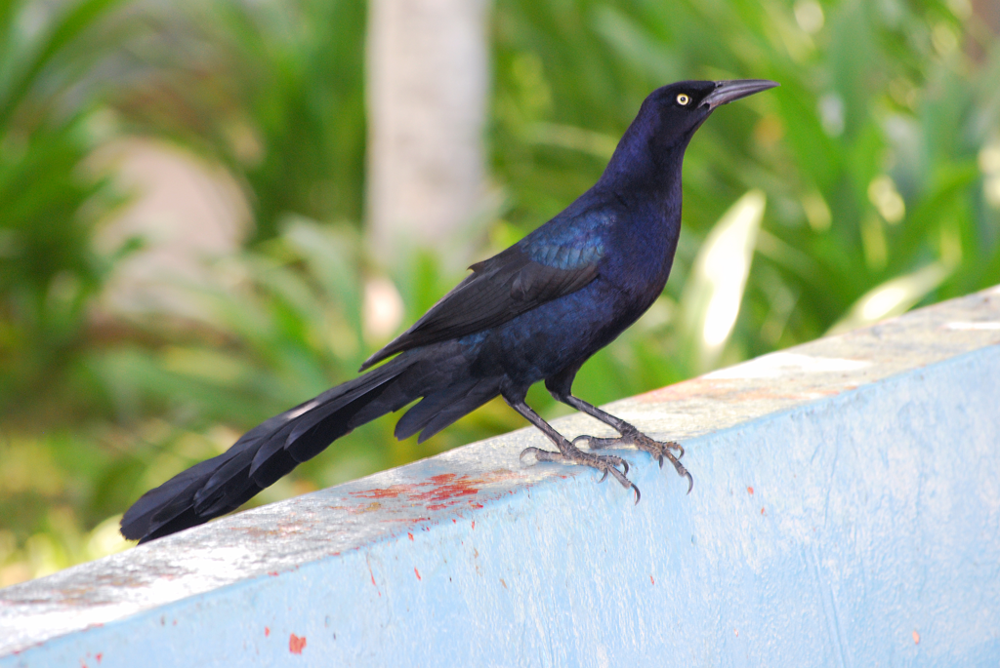
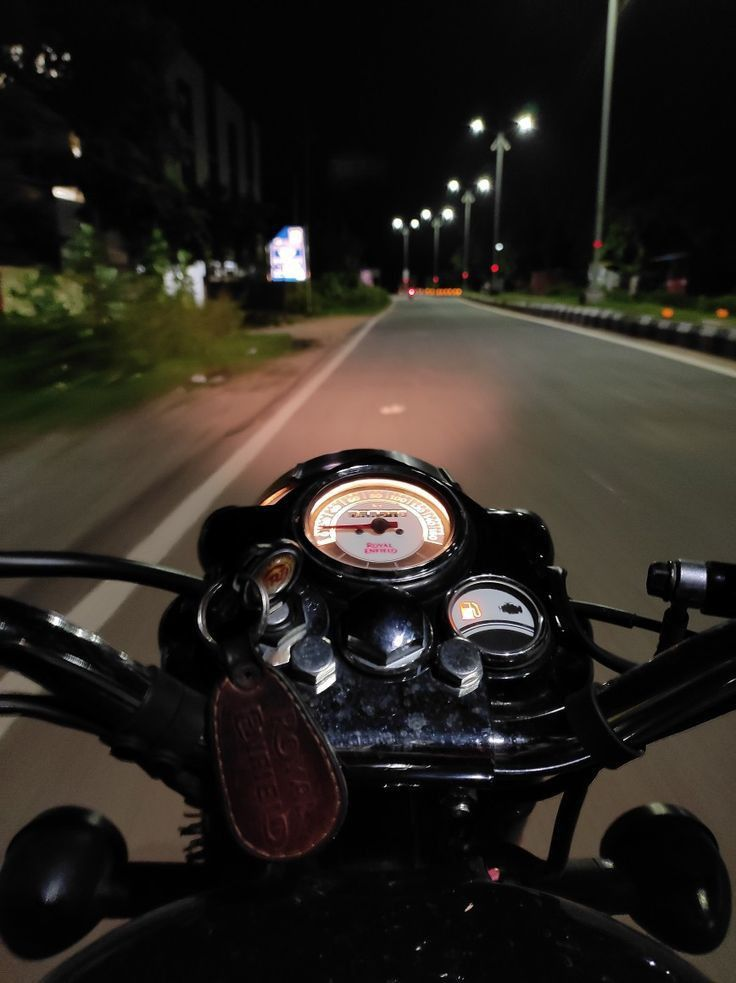
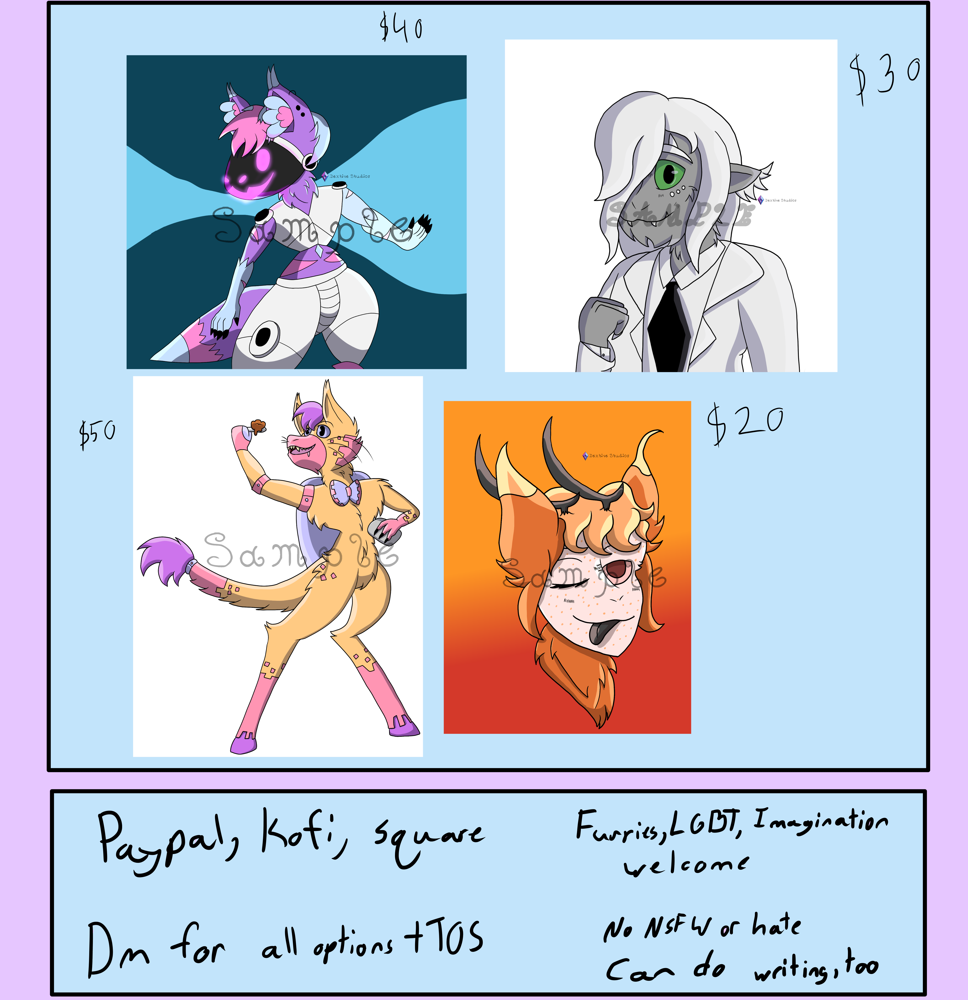
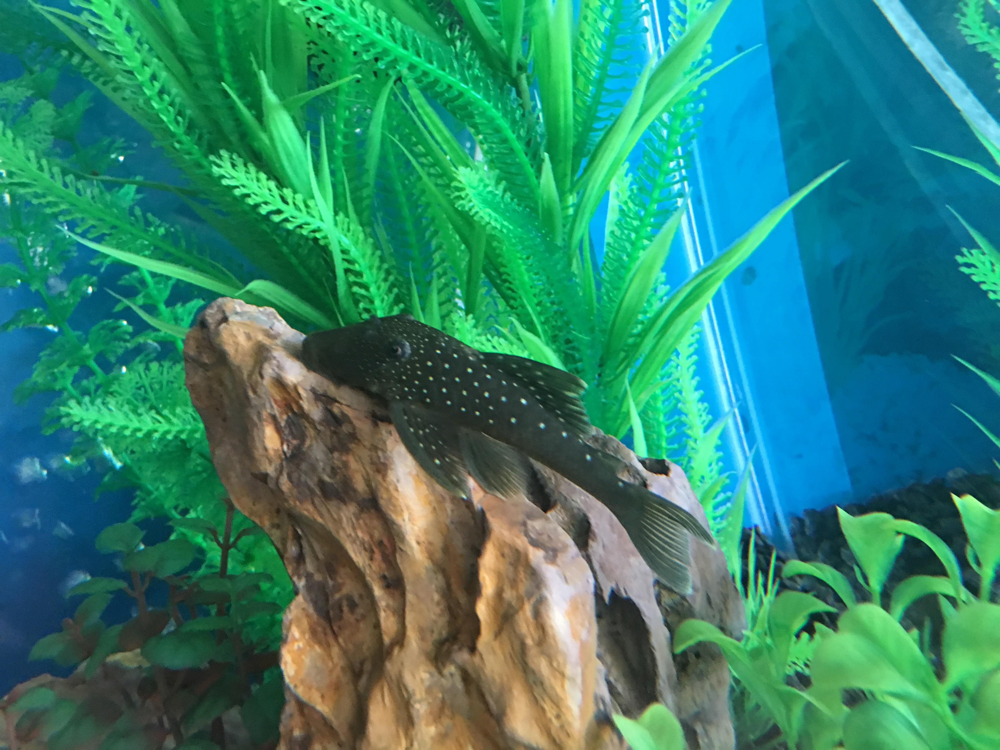
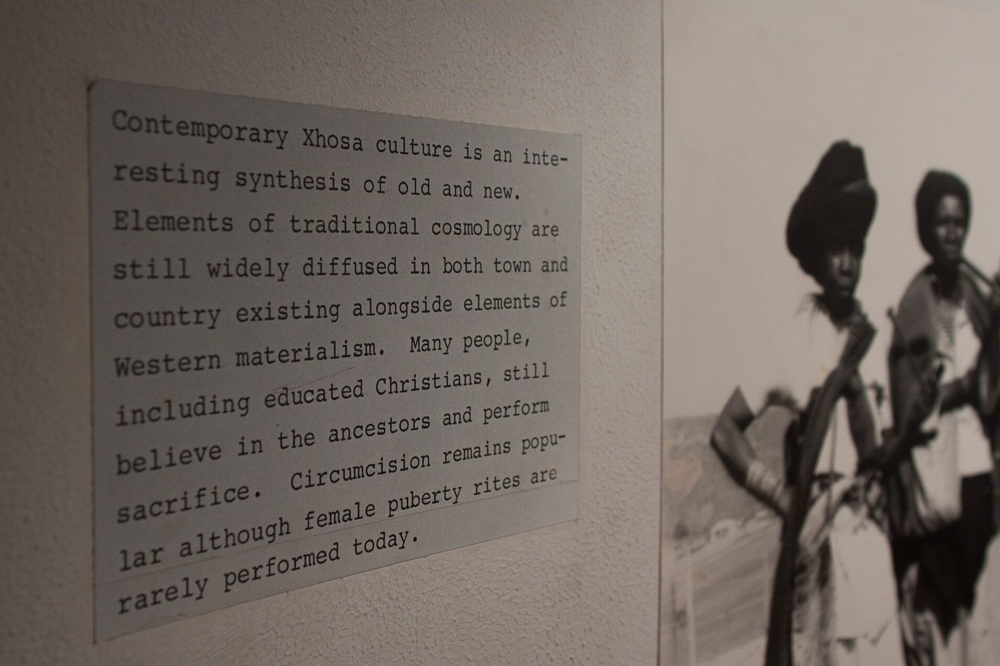
...
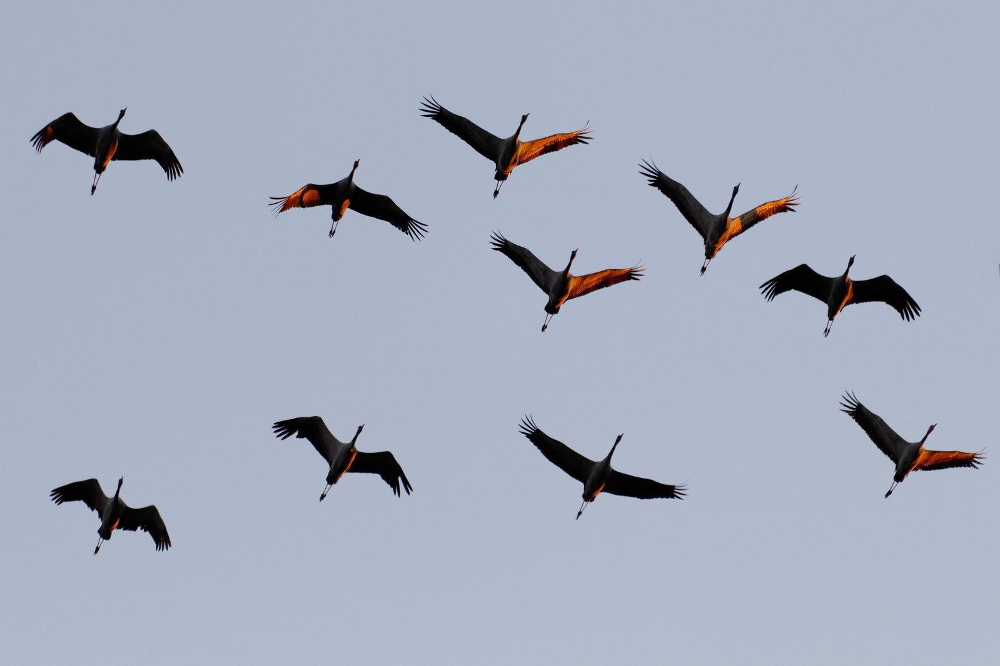
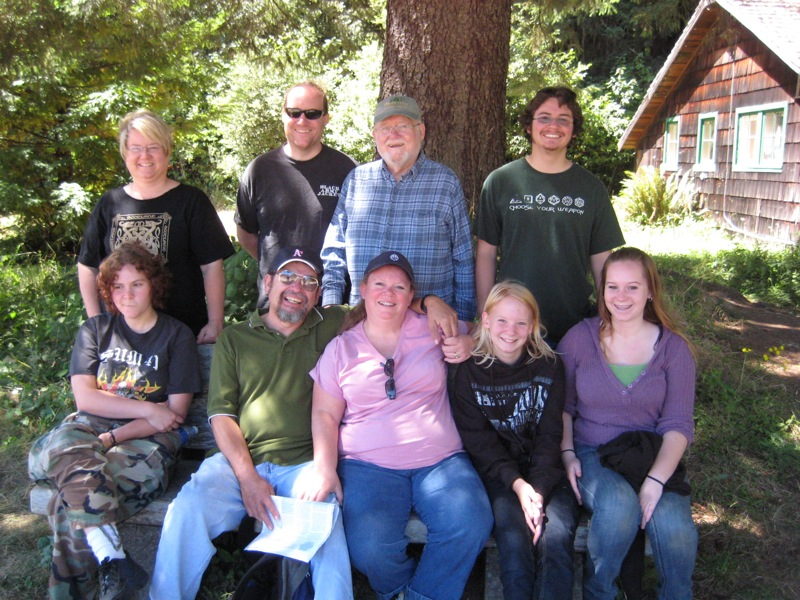
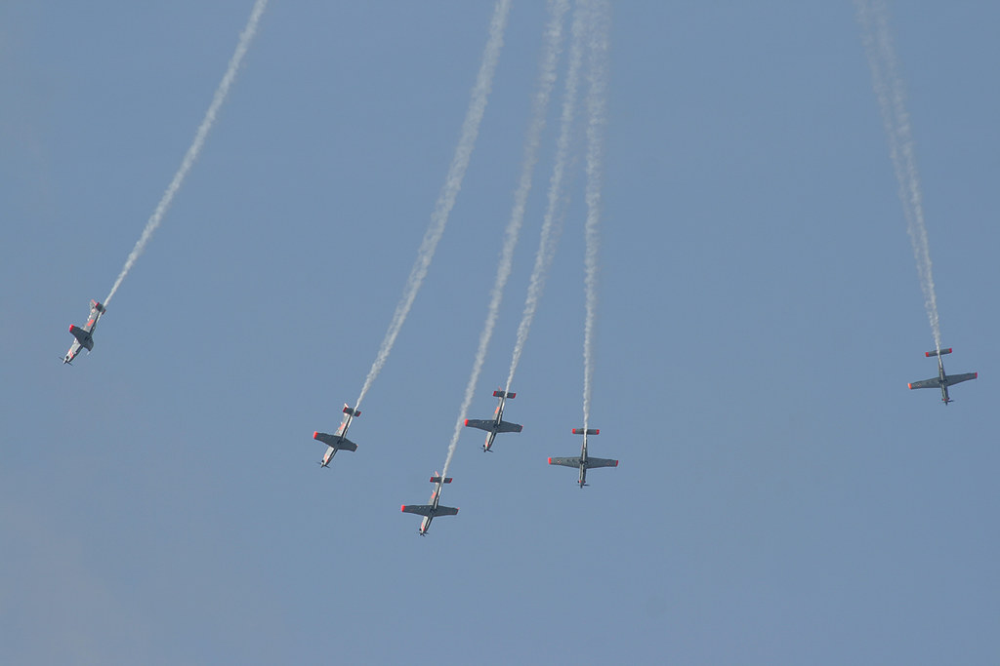
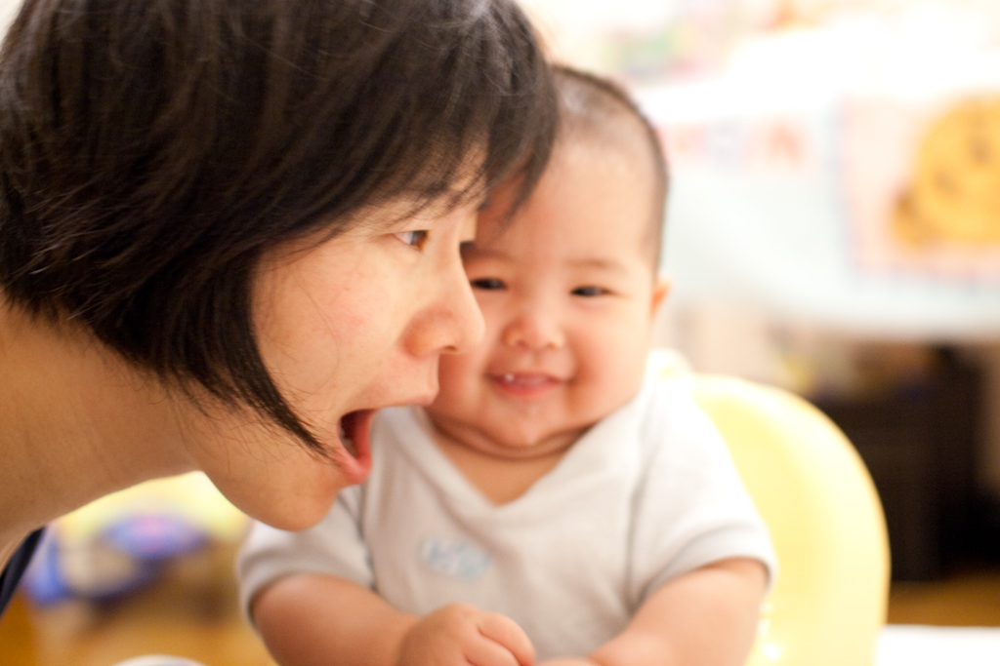
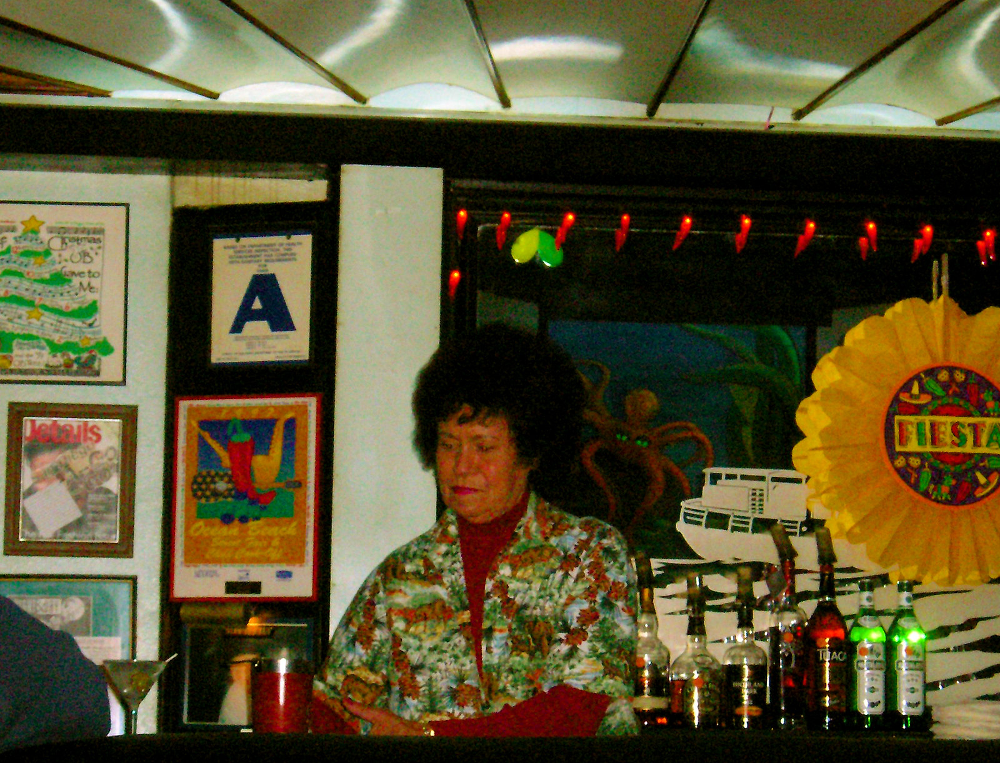

In [11]:
# ===== ВИТРИНА ДЛЯ СДАЧИ: все 20 примеров + моя ручная разметка =====
# Картинки вшиваются в вывод ноутбука (base64) -> видны на любом компьютере,
# без запуска ядра и без папки artifacts. Достаточно открыть .ipynb.
import base64, html
from IPython.display import HTML, display

_MIME = {".jpg": "jpeg", ".jpeg": "jpeg", ".png": "png", ".gif": "gif", ".webp": "webp"}

def _thumb(path, width=260):
    try:
        mime = _MIME.get(Path(path).suffix.lower(), "jpeg")
        data = base64.b64encode(Path(path).read_bytes()).decode()
        return f'<img src="data:image/{mime};base64,{data}" style="width:{width}px;border-radius:6px">'
    except Exception:
        return f'<div style="width:{width}px;height:120px;background:#eee;border-radius:6px;padding-top:50px;text-align:center">нет файла</div>'

rows_v = read_jsonl(review_path)
done_v = [r for r in rows_v if r.get("correctness") is not None]
ok_v = sum(1 for r in done_v if r["correctness"] is True)
et_counts = {}
for r in done_v:
    if r["correctness"] is False:
        key = r.get("error_type") or "other"
        et_counts[key] = et_counts.get(key, 0) + 1

print(f"Ручная разметка: {len(done_v)}/{len(rows_v)} | верно: {ok_v} | неверно: {len(done_v) - ok_v}")
print("Типы ошибок:", et_counts if et_counts else "—")

cards = []
for i, r in enumerate(rows_v):
    if r.get("correctness") is True:    v, col = "ВЕРНО", "#2e7d32"
    elif r.get("correctness") is False: v, col = "НЕВЕРНО", "#c62828"
    else:                               v, col = "НЕ РАЗМЕЧЕНО", "#9e9e9e"
    et = f' · {r["error_type"]}' if r.get("error_type") else ""
    com = f'<div style="color:#555">{html.escape(str(r["comment"]))}</div>' if r.get("comment") else ""
    cards.append(
        '<div style="display:inline-block;width:280px;vertical-align:top;margin:6px;'
        'border:1px solid #ddd;border-radius:10px;padding:8px;font-size:12px;line-height:1.4">'
        + _thumb(r["image"], 260) +
        f'<div style="margin-top:6px"><b>{i+1}. {html.escape(str(r["id"]))}</b> · {r["category"]}</div>'
        f'<div><b>Q:</b> {html.escape(str(r["question"]))[:80]}</div>'
        f'<div><b>Эталон:</b> {html.escape(str(r["reference"]))[:80]}</div>'
        f'<div><b>VLM:</b> {html.escape(str(r["prediction"]))[:100]}</div>'
        f'<div style="color:{col};font-weight:bold;margin-top:3px">{v}{html.escape(et)}</div>{com}</div>')
display(HTML("".join(cards)))

### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
ABL_PROMPTS = {"base": "{q}", "brief": "Look at the image carefully. Answer briefly. {q}"}
ABL_RES = {"r512": 512} if FAST_DEV_RUN else {"r512": 512, "r1024": 1024}
ABL_DECODING = {"greedy": {}, "sampling": {"do_sample": True, "temperature": 0.7, "top_p": 0.9}}

def resize_longest(image, cap):
    w, h = image.size
    s = cap / max(w, h)
    return image if s >= 1 else image.resize((round(w * s), round(h * s)), Image.BICUBIC)

# EM измерим только на VQA/OCR — абляция на одном и том же наборе этих изображений
abl_subset = [ex for ex in examples if ex["category"] in ("open_vqa", "document_qa")]
configs = [{"config_id": f"{p}|{r}|{d}", "prompt_name": p, "prompt": ABL_PROMPTS[p],
            "resolution": ABL_RES[r], "decoding": d, "gen": ABL_DECODING[d]}
           for p in ABL_PROMPTS for r in ABL_RES for d in ABL_DECODING]

abl_path = ARTIFACTS / "ablation.jsonl"
abl_done = {f'{r["config_id"]}::{r["id"]}' for r in read_jsonl(abl_path)}
print(f"Конфигураций: {len(configs)}, примеров: {len(abl_subset)}, "
      f"генераций всего: {len(configs) * len(abl_subset)}, уже готово: {len(abl_done)}")

abl_n = len(abl_done)
with abl_path.open("a", encoding="utf-8") as f:
    for cfg in configs:
        for ex in abl_subset:
            ex_id = f'{ex["task"]}-{ex["source_row"]}'
            key = f'{cfg["config_id"]}::{ex_id}'
            if key in abl_done:
                continue
            image = resize_longest(Image.open(ex["image"]).convert("RGB"), cfg["resolution"])
            q = cfg["prompt"].format(q=ex["question"])
            pred, meta = run_vlm(image, q, gen_overrides={"max_new_tokens": 24 if FAST_DEV_RUN else 64, **cfg["gen"]})
            f.write(json.dumps({"config_id": cfg["config_id"], "prompt_name": cfg["prompt_name"],
                                "prompt": cfg["prompt"], "resolution": cfg["resolution"], "decoding": cfg["decoding"],
                                "id": ex_id, "category": ex["category"], "question": q,
                                "reference": ex["reference"], "prediction": pred,
                                "latency_s": meta["latency_s"], "gen_params": meta["gen_params"]},
                               ensure_ascii=False) + "\n")
            f.flush()
            abl_n += 1
print(f"✔ ablation.jsonl сохранён: {abl_n} генераций")

Конфигураций: 8, примеров: 10, генераций всего: 80, уже готово: 80
✔ ablation.jsonl сохранён: 80 генераций


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
abl_rows = read_jsonl(abl_path)
qual = {}
for r in abl_rows:
    d = qual.setdefault(r["config_id"], {"config_id": r["config_id"], "prompt_name": r["prompt_name"],
                                         "resolution": r["resolution"], "decoding": r["decoding"],
                                         "n": 0, "em": 0.0, "f1": 0.0, "latency": []})
    d["n"] += 1
    d["em"] += exact_match(r["prediction"], r["reference"])
    d["f1"] += token_f1(r["prediction"], r["reference"])
    d["latency"].append(r["latency_s"])
for d in qual.values():
    d["em"] = round(d["em"] / d["n"], 4)
    d["f1"] = round(d["f1"] / d["n"], 4)
    d["median_latency_s"] = float(np.median(d.pop("latency")))

quality = {"mode": "fast_dev_run" if FAST_DEV_RUN else "full",
           "configs": sorted(qual.values(), key=lambda x: -x["em"]),
           "note": "нормализованный EM/F1 на VQA/OCR; у всех вариантов один и тот же набор изображений"}
(ARTIFACTS / "ablation_quality.json").write_text(json.dumps(quality, ensure_ascii=False, indent=2), encoding="utf-8")
for d in quality["configs"]:
    print(f'{d["config_id"]:22s} n={d["n"]:2d}  EM={d["em"]:.2f}  F1={d["f1"]:.2f}  median={d["median_latency_s"]:.2f}s')
print(f'Лучший по EM: {quality["configs"][0]["config_id"]}')
print("✔ ablation_quality.json сохранён")

brief|r512|greedy      n=10  EM=0.30  F1=0.34  median=13.05s
brief|r512|sampling    n=10  EM=0.30  F1=0.36  median=12.98s
brief|r1024|sampling   n=10  EM=0.30  F1=0.36  median=13.60s
base|r512|sampling     n=10  EM=0.20  F1=0.34  median=14.85s
base|r1024|greedy      n=10  EM=0.20  F1=0.37  median=13.89s
brief|r1024|greedy     n=10  EM=0.20  F1=0.34  median=13.65s
base|r512|greedy       n=10  EM=0.10  F1=0.27  median=13.48s
base|r1024|sampling    n=10  EM=0.00  F1=0.28  median=14.06s
Лучший по EM: brief|r512|greedy
✔ ablation_quality.json сохранён


8 конфигураций: 2 промпта (base = вопрос как есть; brief = «Look carefully. Answer briefly») × 2 разрешения (512 / 1024 px) × 2 декодинга (greedy / sampling) на одних и тех же 10 заданиях VQA/OCR = 80 генераций.

### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [14]:
lat = [r["latency_s"] for r in records]
abl_lat = {}
for r in abl_rows:
    abl_lat.setdefault(r["config_id"], []).append(r["latency_s"])

summary = {"model": info, "mode": "fast_dev_run" if FAST_DEV_RUN else "full",
           "n_examples": len(records), "metrics": metrics,
           "latency_main": {"median_s": float(np.median(lat)), "p95_s": float(np.percentile(lat, 95)),
                            "total_s": round(sum(lat), 1)},
           "ablation_quality": quality,
           "ablation_latency": {k: {"median_s": float(np.median(v)), "p95_s": float(np.percentile(v, 95))}
                                for k, v in abl_lat.items()},
           "manual_review": {k: report[k] for k in ("n_total", "n_reviewed", "n_pending", "complete", "error_type_counts")},
           "budget": {"n_generations_total": len(records) + len(abl_rows),
                      "inference_time_s": round(sum(lat) + sum(sum(v) for v in abl_lat.values()), 1)}}
(ARTIFACTS / "eval_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f'Медиана latency (основной прогон): {summary["latency_main"]["median_s"]:.2f}s, '
      f'p95: {summary["latency_main"]["p95_s"]:.2f}s')
print(f'Генераций всего: {summary["budget"]["n_generations_total"]}, '
      f'чистое время инференса: {summary["budget"]["inference_time_s"]}s')
print("✔ eval_summary.json сохранён")

Медиана latency (основной прогон): 15.46s, p95: 25.67s
Генераций всего: 100, чистое время инференса: 1458.6s
✔ eval_summary.json сохранён


### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
RUN_BONUS = True

if not RUN_BONUS:
    print("Бонус пропущен (RUN_BONUS=False)")
else:
    alt_prompt = {"open_vqa": "Answer with a single short phrase. {q}",
                  "document_qa": "Use only text visible in the document image. {q}"}
    picks = []
    for cat in ("open_vqa", "document_qa"):
        ex = next(e for e in examples if e["category"] == cat)
        ex_id = f'{ex["task"]}-{ex["source_row"]}'
        base_pred = next(r["prediction"] for r in records if r["id"] == ex_id)
        image = Image.open(ex["image"]).convert("RGB")
        alt_q = alt_prompt[ex["category"]].format(q=ex["question"])
        alt_pred, meta = run_vlm(image, alt_q)
        picks.append({"id": ex_id, "category": cat, "original_question": ex["question"],
                      "original_answer": base_pred, "alternative_prompt": alt_q,
                      "alternative_answer": alt_pred, "reference": ex["reference"],
                      "original_contains_reference": norm_text(ex["reference"]) in norm_text(base_pred),
                      "alternative_contains_reference": norm_text(ex["reference"]) in norm_text(alt_pred),
                      "latency_s": meta["latency_s"]})
    for p in picks:
        same = norm_text(p["original_answer"]) == norm_text(p["alternative_answer"])
        p["comment"] = ("Ответы совпали — переформулировка не повлияла" if same else
                        "Ответы различаются: формулировка вопроса изменила ответ модели")
        if p["alternative_contains_reference"] and not p["original_contains_reference"]:
            p["comment"] += "; альтернативная формулировка точнее попадает в эталон"
        elif p["original_contains_reference"] and not p["alternative_contains_reference"]:
            p["comment"] += "; исходная формулировка точнее попадает в эталон"
        p["comment"] += " (комментарий можно дополнить своими наблюдениями)"
    (ARTIFACTS / "bonus_prompts.json").write_text(json.dumps(picks, ensure_ascii=False, indent=2), encoding="utf-8")
    for p in picks:
        print(f'{p["id"]}:\n  было:  {p["original_answer"][:70]}\n  стало: {p["alternative_answer"][:70]}\n  {p["comment"]}')
    print("✔ bonus_prompts.json сохранён")

vqa-1:
  было:  This is a Polaroid Spectra System SE camera.
  стало: Polaroid Spectra System SE
  Ответы различаются: формулировка вопроса изменила ответ модели (комментарий можно дополнить своими наблюдениями)
ocr-0:
  было:  The total estimated cost is $2,500.
  стало: $2,500.
  Ответы различаются: формулировка вопроса изменила ответ модели (комментарий можно дополнить своими наблюдениями)
✔ bonus_prompts.json сохранён


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
